# Testing non-linearity

A Cox model with a continuous variable assumes that the log-hazard changes linearly with it. We check that assumption for the haemoglobin (`hb`) in two ways: turning the variable into a factor, and with fractional polynomials.

The data are the survival times, in months, of 48 patients with multiple myeloma. The model has the variables `bun` and `hb`.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2
from lifelines import CoxPHFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
DatOriginal.head()

,time,status,age,sex,bun,ca,hb,pcells,protein
0,13,1,66,1,25,10,14.6,18,1
1,52,0,66,1,13,11,12.0,100,0
2,6,1,53,2,15,13,11.4,33,1
3,40,1,69,1,10,10,10.2,30,1
4,10,1,65,1,20,10,13.2,66,0


Function that calculates the test statistic and $P$-value to compare two nested models based on the log-likelihood ratio test.

In [5]:
def LoglikeRatioTest(minus2loglike_model1, minus2loglike_model2, df_model1, df_model2):
    # model1 must be nested in model2, i.e. model2 has more variables than model1
    test_statistic = minus2loglike_model1 - minus2loglike_model2
    p_value = chi2.sf(test_statistic, df_model2-df_model1)
    return test_statistic, p_value

## The variable as a factor

We create a categorical variable from hb, with its quartiles (0 is the quarter of the patients with the lowest hb, 3 the quarter with the highest). The model that uses it as a factor has a free coefficient for each group; the model that uses the number of the group as a variable forces the coefficients to be on a line. If the first one is not better, a linear term is enough.

In [6]:
DatOriginal['hb_quartiles'] = pd.qcut(DatOriginal['hb'], 4, labels=False)

In [7]:
ModelLinear = CoxPHFitter().fit(DatOriginal, "time", "status", formula='bun+hb_quartiles')
ModelFactor = CoxPHFitter().fit(DatOriginal, "time", "status", formula='bun+C(hb_quartiles)')

MinusTwoLogLikeLinear = -2*ModelLinear.log_likelihood_
MinusTwoLogLikeFactor = -2*ModelFactor.log_likelihood_

DegreesFreedomLinear = len(ModelLinear.summary)
DegreesFreedomFactor = len(ModelFactor.summary)

In [8]:
TestFactor = np.round(LoglikeRatioTest(
    MinusTwoLogLikeLinear,
    MinusTwoLogLikeFactor,
    DegreesFreedomLinear,
    DegreesFreedomFactor
),3)
TestFactor

array([1.703, 0.427])

We conclude that hb is adequately modelled by using a linear term.

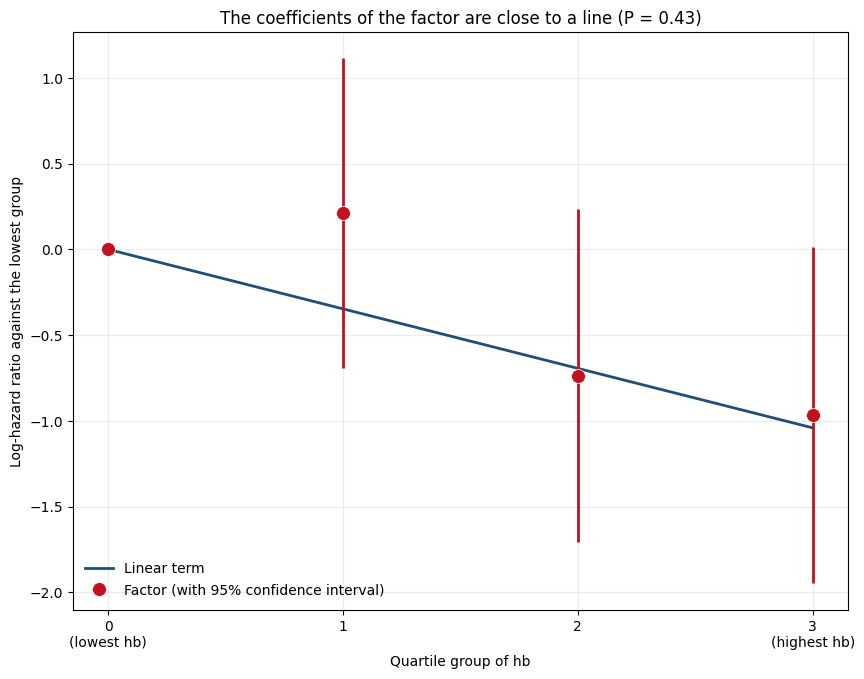

In [9]:
SummaryFactor = ModelFactor.summary.filter(like='hb_quartiles', axis=0)
quartiles = np.arange(4)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.plot(quartiles, ModelLinear.params_['hb_quartiles'] * quartiles, color=line_color, lw=2, label='Linear term')
ax.vlines(quartiles[1:], SummaryFactor['coef lower 95%'], SummaryFactor['coef upper 95%'], color=point_color, lw=2)
ax.plot(quartiles, np.append(0, SummaryFactor['coef']), 'o', color=point_color, markersize=10, markeredgecolor='white',
        markeredgewidth=0.5, label='Factor (with 95% confidence interval)')

ax.set_xticks(quartiles, ['0\n(lowest hb)', '1', '2', '3\n(highest hb)'])
ax.set_xlabel('Quartile group of hb')
ax.set_ylabel('Log-hazard ratio against the lowest group')
ax.set_title(f'The coefficients of the factor are close to a line (P = {TestFactor[1]:.2f})')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)

## Fractional polynomials

A fractional polynomial of degree 1 replaces the linear term $\beta\,\text{hb}$ by $\beta\,\text{hb}^{p}$, with the power $p$ chosen from a fixed set (and $p=0$ meaning $\log\text{hb}$). One of degree 2 uses two powers, $\beta_1\text{hb}^{p_1}+\beta_2\text{hb}^{p_2}$. The power 1 is the linear term, so the comparison of $-2\log\hat L$ shows whether a curve improves on it.

In [10]:
Powers = [-2,-1,-0.5,0,0.5,1,2,3]

In [11]:
# The negative powers of hb take very small values and lifelines warns that those columns have a very
# low variance. It standardizes the variables before fitting, so the fits are not affected.
warnings.filterwarnings('ignore', message='.*have very low variance.*')

### Degree 1

In [12]:
MinusTwoLogLike = []
Aic = []
DegreesFreedom = []

formulas = []

for i,p in enumerate(Powers):
    if p==0:
        f = 'bun+I(log(hb))'
    else:
        f = 'bun+I(hb**'+str(p)+')'

    formulas.append(f)
    cph = CoxPHFitter()
    Model = cph.fit(DatOriginal, 'time', 'status', formula=f)

    if i==0:
        _ = -2*Model.log_likelihood_ + Model.log_likelihood_ratio_test().test_statistic
        MinusTwoLogLike.append(_)
        DegreesFreedom.append(0)
        Aic.append(_)

    MinusTwoLogLike.append(-2*Model.log_likelihood_)
    DegreesFreedom.append(len(Model.summary))
    Aic.append(Model.AIC_partial_)

formulas.insert(0, 'None')

ModelSummary = pd.DataFrame({'p':[None] + Powers, 'formula': formulas, '-2log-L': MinusTwoLogLike, 'AIC': Aic, 'df': DegreesFreedom})

In [13]:
ModelSummary.round(2)

,p,formula,-2log-L,AIC,df
0,NaN,None,214.68,214.68,0
1,-2.0,bun+I(hb**-2),202.22,206.22,2
2,-1.0,bun+I(hb**-1),201.56,205.56,2
3,-0.5,bun+I(hb**-0.5),201.26,205.26,2
4,0.0,bun+I(log(hb)),201.01,205.01,2
5,0.5,bun+I(hb**0.5),200.82,204.82,2
6,1.0,bun+I(hb**1),200.70,204.70,2
7,2.0,bun+I(hb**2),200.69,204.69,2
8,3.0,bun+I(hb**3),200.95,204.95,2


The values of $-2\log\hat L$ are almost the same for all the powers. The difference between the linear term and the best power is far from 3.84, the value needed for a significant improvement with one more parameter.

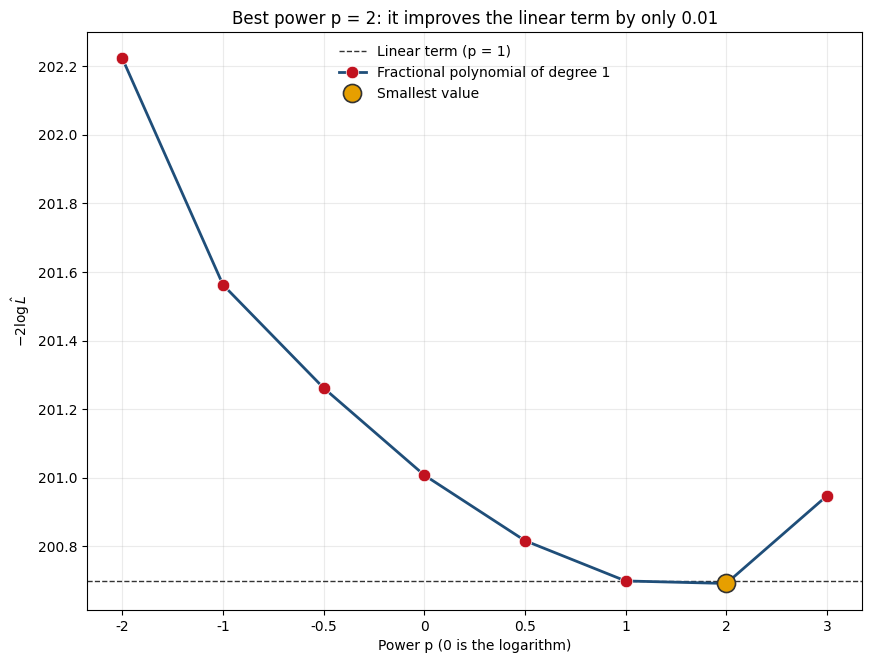

In [14]:
ModelSummaryDegree1 = ModelSummary.iloc[1:].reset_index(drop=True)
Linear = ModelSummaryDegree1.loc[ModelSummaryDegree1['p'] == 1, '-2log-L'].iloc[0]
Best = ModelSummaryDegree1['-2log-L'].argmin()

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axhline(Linear, color=ref_color, lw=1, ls='--', label='Linear term (p = 1)')
ax.plot(ModelSummaryDegree1.index, ModelSummaryDegree1['-2log-L'], '-o', color=line_color, lw=2, markersize=9,
        markerfacecolor=point_color, markeredgecolor='white', markeredgewidth=0.5, label='Fractional polynomial of degree 1')
ax.plot(Best, ModelSummaryDegree1.loc[Best, '-2log-L'], 'o', color=opt_color, markersize=13, markeredgecolor=ref_color,
        markeredgewidth=1.2, label='Smallest value', zorder=5)

ax.set_xticks(ModelSummaryDegree1.index, [str(p) for p in Powers])
ax.set_xlabel('Power p (0 is the logarithm)')
ax.set_ylabel(r'$-2\log\hat L$')
ax.set_title(f"Best power p = {ModelSummaryDegree1.loc[Best, 'p']:g}: "
             f"it improves the linear term by only {Linear - ModelSummaryDegree1.loc[Best, '-2log-L']:.2f}")
ax.legend(loc='upper center', frameon=False)
ax.grid(True, alpha=0.25)

The estimated effect of hb on the log-hazard for each power, relative to the mean hb. In the range of the data all the curves are close to the straight line.

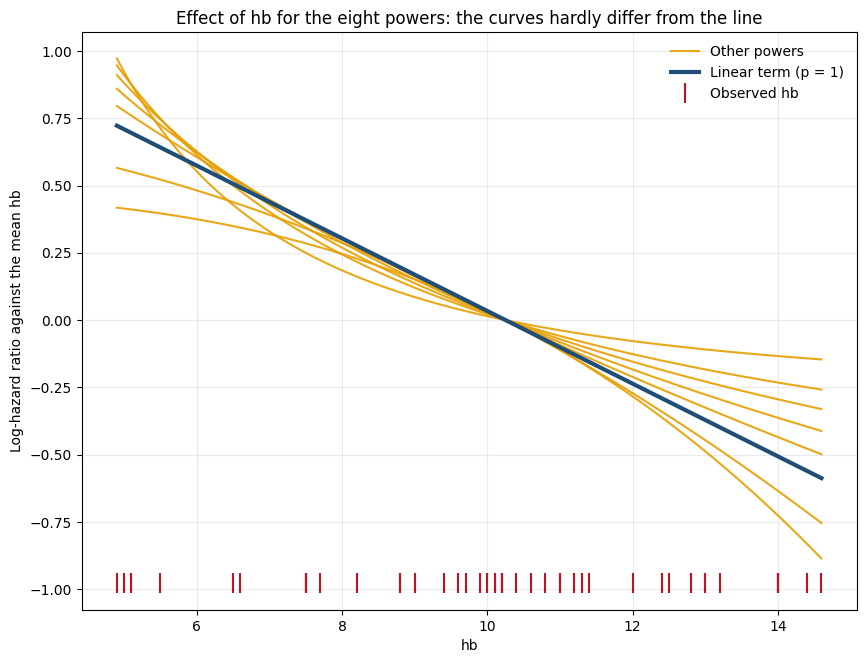

In [15]:
def FractionalPower(x, p):
    return np.log(x) if p == 0 else x**float(p)

hb_grid = np.linspace(DatOriginal['hb'].min(), DatOriginal['hb'].max(), 200)
hb_mean = DatOriginal['hb'].mean()

fig, ax = plt.subplots(figsize=(10, 7.5))
for p in Powers:
    DatPower = DatOriginal.assign(hb_power=FractionalPower(DatOriginal['hb'], p))
    beta = CoxPHFitter().fit(DatPower, 'time', 'status', formula='bun+hb_power').params_['hb_power']
    effect = beta * (FractionalPower(hb_grid, p) - FractionalPower(hb_mean, p))
    if p == 1:
        ax.plot(hb_grid, effect, color=line_color, lw=3, label='Linear term (p = 1)', zorder=4)
    else:
        ax.plot(hb_grid, effect, color=opt_color, lw=1.5, alpha=0.9, label='Other powers' if p == Powers[0] else None)
ax.plot(DatOriginal['hb'], np.full(len(DatOriginal), ax.get_ylim()[0]), '|', color=point_color, markersize=14,
        markeredgewidth=1.5, label='Observed hb')

ax.set_xlabel('hb')
ax.set_ylabel('Log-hazard ratio against the mean hb')
ax.set_title('Effect of hb for the eight powers: the curves hardly differ from the line')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

### Degree 2

In [16]:
MinusTwoLogLike = []
Aic = []
DegreesFreedom = []

formulas = []
p1_list = []
p2_list = []

for i,p1 in enumerate(Powers[:-1]):
    for j,p2 in enumerate(Powers[i+1:]):

        if p1==0:
            f = 'bun+I(log(hb))+'+'I(hb**'+str(p2)+')'
        else:
            f = 'bun+I(hb**'+str(p1)+')+'
            if p2==0:
                f += 'I(log(hb))'
            else:
                f += 'I(hb**'+str(p2)+')'

        formulas.append(f)
        cph = CoxPHFitter()
        Model = cph.fit(DatOriginal, 'time', 'status', formula=f)

        if (i==0) & (j==0):
            _ = -2*Model.log_likelihood_ + Model.log_likelihood_ratio_test().test_statistic
            MinusTwoLogLike.append(_)
            DegreesFreedom.append(0)
            Aic.append(_)

        p1_list.append(p1)
        p2_list.append(p2)
        MinusTwoLogLike.append(-2*Model.log_likelihood_)
        DegreesFreedom.append(len(Model.summary))
        Aic.append(Model.AIC_partial_)

formulas.insert(0, 'None')
p1_list.insert(0, 'None')
p2_list.insert(0, 'None')

ModelSummary = pd.DataFrame({'p1':p1_list, 'p2':p2_list, 'formula': formulas, '-2log-L': MinusTwoLogLike, 'AIC': Aic, 'df': DegreesFreedom})

In [17]:
ModelSummary.round(2)

,p1,p2,formula,-2log-L,AIC,df
0,None,None,None,214.68,214.68,0
1,-2,-1,bun+I(hb**-2)+I(hb**-1),200.46,206.46,3
2,-2,-0.5,bun+I(hb**-2)+I(hb**-0.5),200.45,206.45,3
3,-2,0,bun+I(hb**-2)+I(log(hb)),200.47,206.47,3
4,-2,0.5,bun+I(hb**-2)+I(hb**0.5),200.49,206.49,3
5,-2,1,bun+I(hb**-2)+I(hb**1),200.54,206.54,3
6,-2,2,bun+I(hb**-2)+I(hb**2),200.69,206.69,3
7,-2,3,bun+I(hb**-2)+I(hb**3),200.89,206.89,3
8,-1,-0.5,bun+I(hb**-1)+I(hb**-0.5),200.46,206.46,3
9,-1,0,bun+I(hb**-1)+I(log(hb)),200.48,206.48,3


With two powers the smallest $-2\log\hat L$ is again very close to the one of the linear term, and it uses one more parameter, so every AIC is larger. We keep the linear term for hb.

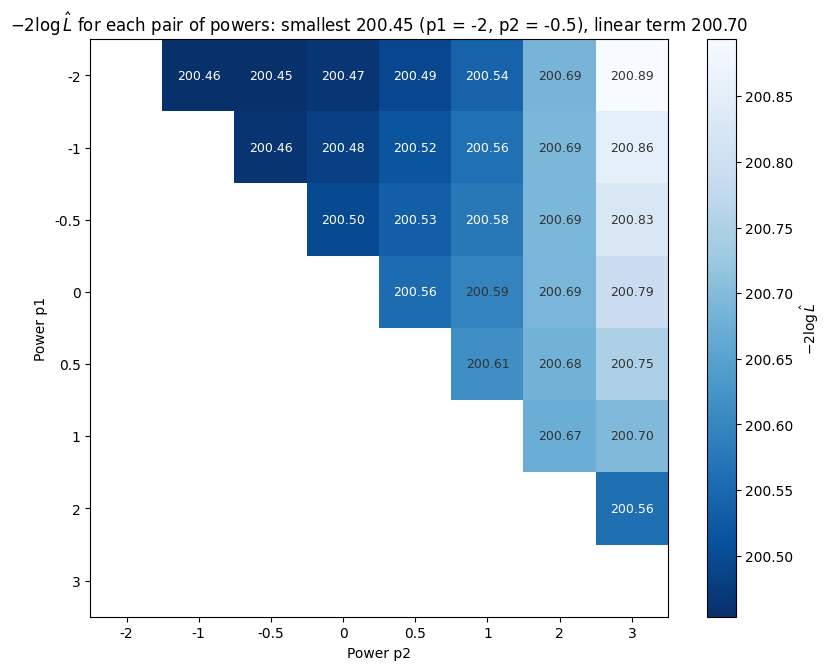

In [18]:
ModelSummaryDegree2 = ModelSummary.iloc[1:]
Grid = pd.DataFrame(np.nan, index=Powers, columns=Powers)
for _, row in ModelSummaryDegree2.iterrows():
    Grid.loc[row['p1'], row['p2']] = row['-2log-L']
BestDegree2 = ModelSummaryDegree2.loc[ModelSummaryDegree2['-2log-L'].astype(float).idxmin()]

fig, ax = plt.subplots(figsize=(10, 7.5))
image = ax.imshow(Grid.to_numpy(dtype=float), cmap='Blues_r')
for i in range(len(Powers)):
    for j in range(len(Powers)):
        value = Grid.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if value < Grid.stack().median() else ref_color)
ax.set_xticks(range(len(Powers)), [str(p) for p in Powers])
ax.set_yticks(range(len(Powers)), [str(p) for p in Powers])
ax.set_xlabel('Power p2')
ax.set_ylabel('Power p1')
ax.set_title(f"$-2\\log\\hat L$ for each pair of powers: smallest {BestDegree2['-2log-L']:.2f} "
             f"(p1 = {BestDegree2['p1']}, p2 = {BestDegree2['p2']}), linear term {Linear:.2f}")
fig.colorbar(image, ax=ax, label=r'$-2\log\hat L$')